# 0. Download Dataset

In [ ]:
!gdown --id '1KSFIRh0-_Vr7SdiSCZP1ItV7bXPxMD92' --output data.tar.gz
!tar -zxvf data.tar.gz
!ls

Downloading...
From: https://drive.google.com/uc?id=1KSFIRh0-_Vr7SdiSCZP1ItV7bXPxMD92
To: /content/data.tar.gz
6.11MB [00:00, 95.7MB/s]
data/
data/sample_submission.csv
data/test_no_label.csv
data/train.csv
data/X_test
data/X_train
data/Y_train
data	     models		    sample_data  submit_generative2.csv
data.tar.gz  output_generative.csv  submit.csv


#### 0.X details

In [ ]:
!cat data/train.csv | head -1
!echo ""
!cat data/train.csv | head -11 | tail -10
!echo ""
!cat data/train.csv | tail -10

id,age,class of worker,detailed industry recode,detailed occupation recode,education,wage per hour,enroll in edu inst last wk,marital stat,major industry code,major occupation code,race,hispanic origin,sex,member of a labor union,reason for unemployment,full or part time employment stat,capital gains,capital losses,dividends from stocks,tax filer stat,region of previous residence,state of previous residence,detailed household and family stat,detailed household summary in household,migration code-change in msa,migration code-change in reg,migration code-move within reg,live in this house 1 year ago,migration prev res in sunbelt,num persons worked for employer,family members under 18,country of birth father,country of birth mother,country of birth self,citizenship,own business or self employed,fill inc questionnaire for veteran's admin,veterans benefits,weeks worked in year,year,y

0,33, Private, 34, 26, Masters degree(MA MS MEng MEd MSW MBA), 0, Not in universe, Married-civilian spouse 

In [ ]:
!cat data/test_no_label.csv | head -5

id,age,class of worker,detailed industry recode,detailed occupation recode,education,wage per hour,enroll in edu inst last wk,marital stat,major industry code,major occupation code,race,hispanic origin,sex,member of a labor union,reason for unemployment,full or part time employment stat,capital gains,capital losses,dividends from stocks,tax filer stat,region of previous residence,state of previous residence,detailed household and family stat,detailed household summary in household,migration code-change in msa,migration code-change in reg,migration code-move within reg,live in this house 1 year ago,migration prev res in sunbelt,num persons worked for employer,family members under 18,country of birth father,country of birth mother,country of birth self,citizenship,own business or self employed,fill inc questionnaire for veteran's admin,veterans benefits,weeks worked in year,year
0,37, Private, 42, 30, Associates degree-occup /vocational, 0, Not in universe, Married-civilian spouse presen

In [ ]:
!cat data/X_train | head -5
!echo
!cat data/X_train | tail -5
!echo
!cat data/X_train | wc -l

id,age, Private, Self-employed-incorporated, State government, Self-employed-not incorporated, Not in universe, Without pay, Federal government, Never worked, Local government, 10, 11, 38, 13, 14, 15, 16, 17, 32, 33, 30, 31, 36, 37, 34, 35, 39, 23, 48, 50, 18, 19, 42, 25, 24, 12, 26, 21, 20, 49, 22, 47, 29, 45, 44, 43, 28, 41, 40, 2, 3, 0, 1, 6, 7, 4, 5, 8, 9, 46, 51, 27, 10, 11, 12, 39, 14, 15, 16, 17, 32, 19, 30, 31, 36, 38, 34, 35, 13, 9, 18, 33, 42, 25, 24, 27, 26, 21, 20, 23, 22, 43, 45, 44, 29, 28, 41, 37, 2, 3, 0, 1, 6, 7, 4, 5, 8, 40, 46, 1st 2nd 3rd or 4th grade, 12th grade no diploma, Less than 1st grade, Some college but no degree, Masters degree(MA MS MEng MEd MSW MBA), 7th and 8th grade, 11th grade, Bachelors degree(BA AB BS), Prof school degree (MD DDS DVM LLB JD), Associates degree-academic program, 5th or 6th grade, Doctorate degree(PhD EdD), Associates degree-occup /vocational, High school graduate, Children, 10th grade, 9th grade,wage per hour, Not in universe, Colleg

In [ ]:
!cat data/Y_train | head -5

id,label
0,1
1,0
2,0
3,0


# 1. TF Dataset

In [ ]:
import tensorflow as tf
tf.executing_eagerly() #check

True

In [ ]:
import numpy as np
import pandas as pd

In [ ]:
df_train_X = pd.read_csv("./data/X_train", sep=',')
tmp_data = pd.DataFrame(df_train_X.iloc[:, 1:])
feat_train_x = tmp_data.to_numpy(dtype=float)

df_train_Y = pd.read_csv("./data/Y_train", sep=',')
tmp_data = pd.DataFrame(df_train_Y.iloc[:, 1:])
label_train_y = tmp_data.to_numpy(dtype=float)

df_test_X = pd.read_csv("./data/X_test", sep=',')
tmp_data = pd.DataFrame(df_test_X.iloc[:, 1:])
feat_test_x = tmp_data.to_numpy(dtype=float)

In [ ]:
def _normalize(X, train = True, specified_column = None, X_mean = None, X_std = None):
    # This function normalizes specific columns of X.
    # The mean and standard variance of training data will be reused when processing testing data.
    #
    # Arguments:
    #     X: data to be processed
    #     train: 'True' when processing training data, 'False' for testing data
    #     specific_column: indexes of the columns that will be normalized. If 'None', all columns
    #         will be normalized.
    #     X_mean: mean value of training data, used when train = 'False'
    #     X_std: standard deviation of training data, used when train = 'False'
    # Outputs:
    #     X: normalized data
    #     X_mean: computed mean value of training data
    #     X_std: computed standard deviation of training data

    if specified_column == None:
        specified_column = np.arange(X.shape[1])
    if train:
        X_mean = np.mean(X[:, specified_column] ,0).reshape(1, -1)
        X_std  = np.std(X[:, specified_column], 0).reshape(1, -1)

    X[:,specified_column] = (X[:, specified_column] - X_mean) / (X_std + 1e-8)
     
    return X, X_mean, X_std


feat_train_x, X_mean, X_std = _normalize(feat_train_x, train = True)
feat_test_x, _, _= _normalize(feat_test_x, train = False, specified_column = None, X_mean = X_mean, X_std = X_std)

In [ ]:
class MkTFDataset(object):
    def __init__(self, arr_x, arr_y, batch_size=128):
        self.batch_size = batch_size
        self.size_fulltraindata = len(arr_x)
        self.fulltrain_dataset = tf.data.Dataset.from_tensor_slices((arr_x, arr_y))
        self.train_dataset = None
        self.valid_dataset = None
        self.fulltrain_dataset_prime = None
        self.Split()

    def Split(self, batch_size=128, ratio=0.8):
        train_size = int(ratio * self.size_fulltraindata)
        self.train_dataset = self.fulltrain_dataset.take(train_size)
        self.train_dataset = self.train_dataset.shuffle(train_size, seed=14522).batch(batch_size)
        self.valid_dataset = self.fulltrain_dataset.skip(train_size).batch(1)
        self.fulltrain_dataset_prime = self.fulltrain_dataset.batch(1)
        #return (self.train_dataset, self.valid_dataset, self.fulltrain_dataset_prime)

In [ ]:
mkdataset = MkTFDataset(feat_train_x, label_train_y)
mkdataset.Split(128, 0.9)

train_dataset = mkdataset.train_dataset
valid_dataset = mkdataset.valid_dataset
fulltrain_dataset = mkdataset.fulltrain_dataset_prime

## 1.X original dataset preparation 

In [ ]:
np.random.seed(0)
X_train_fpath = './data/X_train'
Y_train_fpath = './data/Y_train'
X_test_fpath = './data/X_test'
output_fpath = './output_{}.csv'

# Parse csv files to numpy array
with open(X_train_fpath) as f:
    next(f)
    X_train = np.array([line.strip('\n').split(',')[1:] for line in f], dtype = float)
with open(Y_train_fpath) as f:
    next(f)
    Y_train = np.array([line.strip('\n').split(',')[1] for line in f], dtype = float)
with open(X_test_fpath) as f:
    next(f)
    X_test = np.array([line.strip('\n').split(',')[1:] for line in f], dtype = float)

def _normalize(X, train = True, specified_column = None, X_mean = None, X_std = None):
    # This function normalizes specific columns of X.
    # The mean and standard variance of training data will be reused when processing testing data.
    #
    # Arguments:
    #     X: data to be processed
    #     train: 'True' when processing training data, 'False' for testing data
    #     specific_column: indexes of the columns that will be normalized. If 'None', all columns
    #         will be normalized.
    #     X_mean: mean value of training data, used when train = 'False'
    #     X_std: standard deviation of training data, used when train = 'False'
    # Outputs:
    #     X: normalized data
    #     X_mean: computed mean value of training data
    #     X_std: computed standard deviation of training data

    if specified_column == None:
        specified_column = np.arange(X.shape[1])
    if train:
        X_mean = np.mean(X[:, specified_column] ,0).reshape(1, -1)
        X_std  = np.std(X[:, specified_column], 0).reshape(1, -1)

    X[:,specified_column] = (X[:, specified_column] - X_mean) / (X_std + 1e-8)
     
    return X, X_mean, X_std

def _train_dev_split(X, Y, dev_ratio = 0.25):
    # This function spilts data into training set and development set.
    train_size = int(len(X) * (1 - dev_ratio))
    return X[:train_size], Y[:train_size], X[train_size:], Y[train_size:]

# Normalize training and testing data
X_train, X_mean, X_std = _normalize(X_train, train = True)
X_test, _, _= _normalize(X_test, train = False, specified_column = None, X_mean = X_mean, X_std = X_std)
    
# Split data into training set and development set
dev_ratio = 0.1
X_train, Y_train, X_dev, Y_dev = _train_dev_split(X_train, Y_train, dev_ratio = dev_ratio)

train_size = X_train.shape[0]
dev_size = X_dev.shape[0]
test_size = X_test.shape[0]
data_dim = X_train.shape[1]
print('Size of training set: {}'.format(train_size))
print('Size of development set: {}'.format(dev_size))
print('Size of testing set: {}'.format(test_size))
print('Dimension of data: {}'.format(data_dim))

Size of training set: 48830
Size of development set: 5426
Size of testing set: 27622
Dimension of data: 510


In [ ]:
X_train.shape

(48830, 510)

# 1. Training (Discriminative Model)

* Model

In [ ]:
dim_feat = feat_train_x.shape[1]
print("dim_feat=", dim_feat)

class LinearClassificationModel(tf.keras.Model):
    def __init__(self, n_vals=1):
        super(LinearClassificationModel, self).__init__()
        self.denseout = tf.keras.layers.Dense(units=n_vals, input_shape=(dim_feat, ), activation=tf.keras.activations.sigmoid)

    def call(self, input):
        result = self.denseout(input)
        return result

dim_feat= 510


* Learner

In [ ]:
tf.keras.backend.set_floatx('float64')

In [ ]:
class Learner(object):
    def __init__(self, mkdataset, ratio_valid=0.1, train_batch_size=128):
        self.train_batch_size = train_batch_size
        self.num_epochs = 100
        self.num_epochs_validation = 10
        self.model = LinearClassificationModel(n_vals=1)
        mkdataset.Split(batch_size=train_batch_size, ratio=1-ratio_valid)
        self.train_dataset = mkdataset.train_dataset
        self.valid_dataset = mkdataset.valid_dataset
        self.fulltrain_dataset = mkdataset.fulltrain_dataset_prime
        self.optimizer = tf.keras.optimizers.Adam(learning_rate=0.001, beta_1=0.8, beta_2=0.99, epsilon=1e-07)
        self.train_loss = tf.keras.metrics.Mean(name='train_loss')
        self.valid_loss = tf.keras.metrics.Mean(name='valid_loss')
        self.train_acc = tf.keras.metrics.Mean(name='train_acc')
        self.valid_acc = tf.keras.metrics.Mean(name='valid_acc')

    @tf.function
    def train_step(self, features, labels):
        with tf.GradientTape() as tape:
          predictions = tf.squeeze(self.model(features), axis=1)
          labels = tf.squeeze(labels, axis=1)
          loss = tf.keras.losses.binary_crossentropy(y_true=labels, y_pred=predictions)
        gradients = tape.gradient(loss, self.model.trainable_variables)
        self.optimizer.apply_gradients(zip(gradients, self.model.trainable_variables))
        self.train_loss(loss)
        self.train_acc(tf.keras.metrics.binary_accuracy(y_true=labels, y_pred=predictions))

    @tf.function
    def valid_step(self, features, labels):
        with tf.GradientTape() as tape:
          predictions = tf.squeeze(self.model(features), axis=1)
          labels = tf.squeeze(labels, axis=1)
          loss = tf.keras.losses.binary_crossentropy(y_true=labels, y_pred=predictions)    
        self.valid_loss(loss)
        self.valid_acc(tf.keras.metrics.binary_accuracy(y_true=labels, y_pred=predictions))

    def train(self):
        for epoch in range(self.num_epochs):
            self.train_loss.reset_states()
            self.valid_loss.reset_states()
            
            for features, labels in self.train_dataset:
                self.train_step(features, labels)

            if epoch % self.num_epochs_validation == self.num_epochs_validation - 1:
                for features, labels in self.valid_dataset:
                    self.valid_step(features, labels)
                #for features, labels in self.train_dataset:
                #    self.valid_step(features, labels)
                template = 'Epoch {}, Loss: {}, BinaryAccurancy:{}, Valid Loss: {}, Valid BinaryAccurancy:{}'
                print(template.format(epoch + 1,
                                      self.train_loss.result(),
                                      self.train_acc.result(),
                                      self.valid_loss.result(),
                                      self.valid_acc.result()))


* find parameters

In [ ]:
learner = Learner(mkdataset, 0.1, 128)
learner.optimizer = tf.keras.optimizers.Adam(learning_rate=0.001, beta_1=0.75, beta_2=0.99, epsilon=1e-09)
learner.num_epochs = 20
learner.num_epochs_validation = 10

learner.train()

Epoch 10, Loss: 0.27524294384788656, BinaryAccurancy:0.8622619041335925, Valid Loss: 0.2911542569794902, Valid BinaryAccurancy:0.8767047548838923
Epoch 20, Loss: 0.27393773720479664, BinaryAccurancy:0.8731123859989864, Valid Loss: 0.2909097733459392, Valid BinaryAccurancy:0.876889052709178


* train whole training set

In [ ]:
learner = Learner(mkdataset, 0.0, 128)
learner.optimizer = tf.keras.optimizers.Adam(learning_rate=0.001, beta_1=0.75, beta_2=0.99, epsilon=1e-09)
learner.num_epochs = 20
learner.num_epochs_validation = 10

learner.train()

Epoch 10, Loss: 0.27560637383930203, BinaryAccurancy:0.863543947944744, Valid Loss: 0.0, Valid BinaryAccurancy:0.0
Epoch 20, Loss: 0.27452069012588554, BinaryAccurancy:0.8733849867334904, Valid Loss: 0.0, Valid BinaryAccurancy:0.0


* save model

In [ ]:
learner.model.save("models/v00/model_fulldataset.tf", save_format="tf")
!tar cvf models/v00.tar models/v00/*
!ls -l models

INFO:tensorflow:Assets written to: models/v00/model_fulldataset.tf/assets
models/v00/model_fulldataset.tf/
models/v00/model_fulldataset.tf/variables/
models/v00/model_fulldataset.tf/variables/variables.index
models/v00/model_fulldataset.tf/variables/variables.data-00000-of-00001
models/v00/model_fulldataset.tf/saved_model.pb
models/v00/model_fulldataset.tf/assets/
total 44
drwxr-xr-x 3 root root  4096 Oct  3 02:45 v00
-rw-r--r-- 1 root root 40960 Oct  3 05:21 v00.tar


In [ ]:
from google.colab import files
#files.download('models/v00.tar')

#### details: parameters

just trying... not optimized

In [ ]:
#learner = Learner(mkdataset, 0.1, 32)
#learner.optimizer = tf.keras.optimizers.Adam(learning_rate=0.001, beta_1=0.9, beta_2=0.999, epsilon=1e-07)
"""
Epoch 5, Loss: 0.2810423362624507, BinaryAccurancy:0.867831749672346, Valid Loss: 0.29455457268251245, Valid BinaryAccurancy:0.8743088831551787
Epoch 10, Loss: 0.2795408670162271, BinaryAccurancy:0.8748966524683266, Valid Loss: 0.2959075609609496, Valid BinaryAccurancy:0.874769627718393
"""

'\nEpoch 5, Loss: 0.2810423362624507, BinaryAccurancy:0.867831749672346, Valid Loss: 0.29455457268251245, Valid BinaryAccurancy:0.8743088831551787\nEpoch 10, Loss: 0.2795408670162271, BinaryAccurancy:0.8748966524683266, Valid Loss: 0.2959075609609496, Valid BinaryAccurancy:0.874769627718393\n'

In [ ]:
#learner = Learner(mkdataset, 0.1, 128)
#learner.optimizer = tf.keras.optimizers.Adam(learning_rate=0.001, beta_1=0.9, beta_2=0.999, epsilon=1e-07)
"""
Epoch 5, Loss: 0.3099751063121197, BinaryAccurancy:0.8387640390136801, Valid Loss: 0.3155131855518307, Valid BinaryAccurancy:0.8698857353483229
Epoch 10, Loss: 0.2787955438400095, BinaryAccurancy:0.8604796487079887, Valid Loss: 0.29342740639954284, Valid BinaryAccurancy:0.8735716918540362
"""

'\nEpoch 5, Loss: 0.3099751063121197, BinaryAccurancy:0.8387640390136801, Valid Loss: 0.3155131855518307, Valid BinaryAccurancy:0.8698857353483229\nEpoch 10, Loss: 0.2787955438400095, BinaryAccurancy:0.8604796487079887, Valid Loss: 0.29342740639954284, Valid BinaryAccurancy:0.8735716918540362\n'

In [ ]:
#learner = Learner(mkdataset, 0.1, 16)
#learner.optimizer = tf.keras.optimizers.Adam(learning_rate=0.001, beta_1=0.9, beta_2=0.999, epsilon=1e-07)
"""
Epoch 5, Loss: 0.3158510853421767, BinaryAccurancy:0.8700881155214379, Valid Loss: 0.3419545103410094, Valid BinaryAccurancy:0.869332841872466
Epoch 10, Loss: 0.3150024797353313, BinaryAccurancy:0.874576975285527, Valid Loss: 0.34374871165156673, Valid BinaryAccurancy:0.8707150755621084
"""

'\nEpoch 5, Loss: 0.3158510853421767, BinaryAccurancy:0.8700881155214379, Valid Loss: 0.3419545103410094, Valid BinaryAccurancy:0.869332841872466\nEpoch 10, Loss: 0.3150024797353313, BinaryAccurancy:0.874576975285527, Valid Loss: 0.34374871165156673, Valid BinaryAccurancy:0.8707150755621084\n'

In [ ]:
#learner = Learner(mkdataset, 0.1, 128)
#learner.optimizer = tf.keras.optimizers.Adam(learning_rate=0.01, beta_1=0.9, beta_2=0.999, epsilon=1e-07)
"""
Epoch 5, Loss: 0.34576903216878485, BinaryAccurancy:0.8663251034453641, Valid Loss: 0.3738281679920261, Valid BinaryAccurancy:0.8643568005897531
Epoch 10, Loss: 0.34582077133125527, BinaryAccurancy:0.8684868344663065, Valid Loss: 0.3847716900941598, Valid BinaryAccurancy:0.8630667158127534
"""

'\nEpoch 5, Loss: 0.34576903216878485, BinaryAccurancy:0.8663251034453641, Valid Loss: 0.3738281679920261, Valid BinaryAccurancy:0.8643568005897531\nEpoch 10, Loss: 0.34582077133125527, BinaryAccurancy:0.8684868344663065, Valid Loss: 0.3847716900941598, Valid BinaryAccurancy:0.8630667158127534\n'

In [ ]:
#learner = Learner(mkdataset, 0.1, 128)
#learner.optimizer = tf.keras.optimizers.Adam(learning_rate=0.003, beta_1=0.9, beta_2=0.999, epsilon=1e-09)
"""
Epoch 5, Loss: 0.2885181674477372, BinaryAccurancy:0.865267295431515, Valid Loss: 0.29679179481102763, Valid BinaryAccurancy:0.8741245853298931
Epoch 10, Loss: 0.2870003240391008, BinaryAccurancy:0.8728804915765919, Valid Loss: 0.29794874105123825, Valid BinaryAccurancy:0.8744931809804645
"""

'\nEpoch 5, Loss: 0.2885181674477372, BinaryAccurancy:0.865267295431515, Valid Loss: 0.29679179481102763, Valid BinaryAccurancy:0.8741245853298931\nEpoch 10, Loss: 0.2870003240391008, BinaryAccurancy:0.8728804915765919, Valid Loss: 0.29794874105123825, Valid BinaryAccurancy:0.8744931809804645\n'

In [ ]:
#learner = Learner(mkdataset, 0.1, 128)
#learner.optimizer = tf.keras.optimizers.Adam(learning_rate=0.001, beta_1=0.75, beta_2=0.99, epsilon=1e-09)
"""
Epoch 5, Loss: 0.2896611691772782, BinaryAccurancy:0.8418786153099139, Valid Loss: 0.2993275294308496, Valid BinaryAccurancy:0.8743088831551787
Epoch 10, Loss: 0.27295421402477865, BinaryAccurancy:0.8626894739064348, Valid Loss: 0.29121522939383815, Valid BinaryAccurancy:0.8755068190195355
"""

"""
Epoch 10, Loss: 0.2753939095732031, BinaryAccurancy:0.8635031825282893, Valid Loss: 0.2938544766733764, Valid BinaryAccurancy:0.8767047548838923
Epoch 20, Loss: 0.2742141363420892, BinaryAccurancy:0.8737351363262115, Valid Loss: 0.2936648998141878, Valid BinaryAccurancy:0.8767969037965352
Epoch 30, Loss: 0.27406263985401186, BinaryAccurancy:0.8771601916554072, Valid Loss: 0.2944628408436991, Valid BinaryAccurancy:0.8767661874923209
Epoch 40, Loss: 0.2742813385507181, BinaryAccurancy:0.8789044027613577, Valid Loss: 0.29478369839661095, Valid BinaryAccurancy:0.876658680427571
"""

'\nEpoch 10, Loss: 0.2753939095732031, BinaryAccurancy:0.8635031825282893, Valid Loss: 0.2938544766733764, Valid BinaryAccurancy:0.8767047548838923\nEpoch 20, Loss: 0.2742141363420892, BinaryAccurancy:0.8737351363262115, Valid Loss: 0.2936648998141878, Valid BinaryAccurancy:0.8767969037965352\nEpoch 30, Loss: 0.27406263985401186, BinaryAccurancy:0.8771601916554072, Valid Loss: 0.2944628408436991, Valid BinaryAccurancy:0.8767661874923209\nEpoch 40, Loss: 0.2742813385507181, BinaryAccurancy:0.8789044027613577, Valid Loss: 0.29478369839661095, Valid BinaryAccurancy:0.876658680427571\n'

#### details

In [ ]:
test_learner = Learner(mkdataset, 0.1, 64)
test_learner.optimizer = tf.keras.optimizers.SGD(learning_rate=0.2, momentum=0.0, nesterov=False)
test_learner.num_epochs = 10
test_learner.num_epochs_validation = 2

test_learner.train()

Epoch 2, Loss: 0.3060989546407749, BinaryAccurancy:0.8664449937640045, Valid Loss: 0.3295712840742656, Valid BinaryAccurancy:0.8652782897161814
Epoch 4, Loss: 0.3078627051696697, BinaryAccurancy:0.8688510376590708, Valid Loss: 0.31845504054963897, Valid BinaryAccurancy:0.867121267969038
Epoch 6, Loss: 0.305666758212497, BinaryAccurancy:0.8696803567905411, Valid Loss: 0.31958025368984583, Valid BinaryAccurancy:0.867674161444895
Epoch 8, Loss: 0.3062991208616912, BinaryAccurancy:0.8703282055923137, Valid Loss: 0.3231544852147353, Valid BinaryAccurancy:0.8667526723184666
Epoch 10, Loss: 0.3073008017794672, BinaryAccurancy:0.8705363088191772, Valid Loss: 0.3252285998306043, Valid BinaryAccurancy:0.8664209362329525


In [ ]:
for idx, (features, labels) in enumerate(learner.valid_dataset):
  if idx>=5:
    continue
  predictions = tf.squeeze(learner.model(features), axis=1)
  labels = tf.squeeze(labels, axis=1)   
  loss = tf.keras.losses.binary_crossentropy(labels, predictions) 
  print("prediction = ", predictions)
  print("labels = ", labels)
  print("loss = ", loss)
  print()

## 1.X original training

In [ ]:
# util funcs
def _shuffle(X, Y):
    # This function shuffles two equal-length list/array, X and Y, together.
    randomize = np.arange(len(X))
    np.random.shuffle(randomize)
    return (X[randomize], Y[randomize])

def _sigmoid(z):
    # Sigmoid function can be used to calculate probability.
    # To avoid overflow, minimum/maximum output value is set.
    return np.clip(1 / (1.0 + np.exp(-z)), 1e-8, 1 - (1e-8))

def _f(X, w, b):
    # This is the logistic regression function, parameterized by w and b
    #
    # Arguements:
    #     X: input data, shape = [batch_size, data_dimension]
    #     w: weight vector, shape = [data_dimension, ]
    #     b: bias, scalar
    # Output:
    #     predicted probability of each row of X being positively labeled, shape = [batch_size, ]
    return _sigmoid(np.matmul(X, w) + b)

def _predict(X, w, b):
    # This function returns a truth value prediction for each row of X 
    # by rounding the result of logistic regression function.
    return np.round(_f(X, w, b)).astype(np.int)
    
def _accuracy(Y_pred, Y_label):
    # This function calculates prediction accuracy
    acc = 1 - np.mean(np.abs(Y_pred - Y_label))
    return acc

In [ ]:
#loss functions
def _cross_entropy_loss(y_pred, Y_label):
    # This function computes the cross entropy.
    #
    # Arguements:
    #     y_pred: probabilistic predictions, float vector
    #     Y_label: ground truth labels, bool vector
    # Output:
    #     cross entropy, scalar
    cross_entropy = -np.dot(Y_label, np.log(y_pred)) - np.dot((1 - Y_label), np.log(1 - y_pred))
    return cross_entropy

def _gradient(X, Y_label, w, b):
    # This function computes the gradient of cross entropy loss with respect to weight w and bias b.
    y_pred = _f(X, w, b)
    pred_error = Y_label - y_pred
    w_grad = -np.sum(pred_error * X.T, 1)
    b_grad = -np.sum(pred_error)
    return w_grad, b_grad


In [ ]:
#training
# Zero initialization for weights ans bias
w = np.zeros((data_dim,)) 
b = np.zeros((1,))

# Some parameters for training    
max_iter = 10
batch_size = 8
learning_rate = 0.2

# Keep the loss and accuracy at every iteration for plotting
train_loss = []
dev_loss = []
train_acc = []
dev_acc = []

# Calcuate the number of parameter updates
step = 1

# Iterative training
for epoch in range(max_iter):
    # Random shuffle at the begging of each epoch
    X_train, Y_train = _shuffle(X_train, Y_train)
        
    # Mini-batch training
    for idx in range(int(np.floor(train_size / batch_size))):
        X = X_train[idx*batch_size:(idx+1)*batch_size]
        Y = Y_train[idx*batch_size:(idx+1)*batch_size]

        # Compute the gradient
        w_grad, b_grad = _gradient(X, Y, w, b)
            
        # gradient descent update
        # learning rate decay with time
        w = w - learning_rate/np.sqrt(step) * w_grad
        b = b - learning_rate/np.sqrt(step) * b_grad

        step = step + 1
            
    # Compute loss and accuracy of training set and development set
    y_train_pred = _f(X_train, w, b)
    Y_train_pred = np.round(y_train_pred)
    train_acc.append(_accuracy(Y_train_pred, Y_train))
    train_loss.append(_cross_entropy_loss(y_train_pred, Y_train) / train_size)

    y_dev_pred = _f(X_dev, w, b)
    Y_dev_pred = np.round(y_dev_pred)
    dev_acc.append(_accuracy(Y_dev_pred, Y_dev))
    dev_loss.append(_cross_entropy_loss(y_dev_pred, Y_dev) / dev_size)

print('Training loss: {}'.format(train_loss[-1]))
print('Development loss: {}'.format(dev_loss[-1]))
print('Training accuracy: {}'.format(train_acc[-1]))
print('Development accuracy: {}'.format(dev_acc[-1]))

Training loss: 0.27135543524640593
Development loss: 0.2896359675026287
Training accuracy: 0.8836166291214418
Development accuracy: 0.8733873940287504


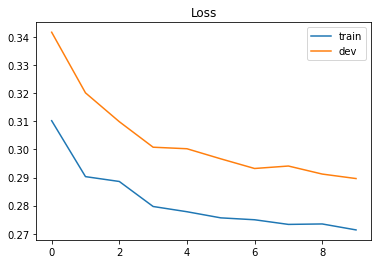

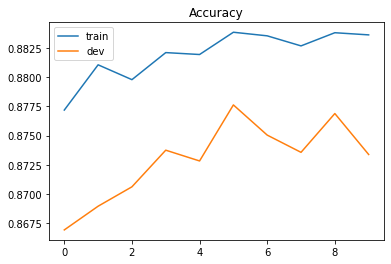

In [ ]:
#plots

import matplotlib.pyplot as plt

# Loss curve
plt.plot(train_loss)
plt.plot(dev_loss)
plt.title('Loss')
plt.legend(['train', 'dev'])
plt.savefig('loss.png')
plt.show()

# Accuracy curve
plt.plot(train_acc)
plt.plot(dev_acc)
plt.title('Accuracy')
plt.legend(['train', 'dev'])
plt.savefig('acc.png')
plt.show()

# 2. Predict (Discriminative Model)

In [ ]:
test_dataset = tf.data.Dataset.from_tensor_slices(feat_test_x).batch(1)

In [ ]:
predict_test = np.empty(len(test_dataset))
for idx, features in enumerate(test_dataset):
  predictions = tf.squeeze(learner.model(features), axis=1)
  predict_test[idx] = predictions.numpy()[0]

predict_test[0:5]

array([0.04010924, 0.40833033, 0.00703709, 0.30479482, 0.00271218])

In [ ]:
import csv
with open('submit.csv', mode='w', newline='') as submit_file:
    csv_writer = csv.writer(submit_file)
    header = ['id', 'label']
    csv_writer.writerow(header)
    for idx in range(len(test_dataset)):
        row = [str(idx), 1 if predict_test[idx]>0.5 else 0]
        csv_writer.writerow(row)

In [ ]:
!cat submit.csv | head -20  # score : 0.88769  private: 0.89030

id,label
0,0
1,0
2,0
3,0
4,0
5,1
6,0
7,1
8,0
9,0
10,0
11,0
12,1
13,0
14,0
15,0
16,0
17,0
18,0


In [ ]:
files.download('submit.csv') 

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

#### details

In [ ]:
!wc -l submit.csv

27623 submit.csv


In [ ]:
with open('submit.csvx', mode='w', newline='') as submit_file:
    csv_writer = csv.writer(submit_file)
    header = ['id', 'value']
    csv_writer.writerow(header)
    for idx in range(len(test_dataset)):
        row = ['id_' + str(idx), predict_test[idx]]
        csv_writer.writerow(row)

In [ ]:
!cat submit.csvx | head -20

id,value
id_0,0.04012801434627307
id_1,0.4081462410240825
id_2,0.007019567078188753
id_3,0.30531173539879347
id_4,0.0027342425659804244
id_5,0.5421923982260992
id_6,0.00013929719850495843
id_7,0.9338141523061607
id_8,0.018656415092158207
id_9,0.01097762689711057
id_10,0.0008424462203887452
id_11,0.023816693461383612
id_12,0.8599555709810025
id_13,0.015869916483462306
id_14,0.01662332344634183
id_15,0.49635579833188453
id_16,0.06944083420173994
id_17,0.14115023184008607
id_18,0.0002847566976895463


## 2.X original prediction

In [ ]:
#predict
# Predict testing labels
predictions = _predict(X_test, w, b)
with open(output_fpath.format('logistic'), 'w') as f:
    f.write('id,label\n')
    for i, label in  enumerate(predictions):
        f.write('{},{}\n'.format(i, label))

# Print out the most significant weights
ind = np.argsort(np.abs(w))[::-1]
with open(X_test_fpath) as f:
    content = f.readline().strip('\n').split(',')
features = np.array(content)
for i in ind[0:10]:
    print(features[i], w[i])

 29 -9.5791015625
 Forestry and fisheries 9.53662109375
 Retail trade 8.13671875
 7 -7.81689453125
 Finance insurance and real estate 7.6845703125
 41 -7.138671875
 Agriculture 6.975830078125
 34 -6.2109375
 37 -5.69384765625
 33 -5.6201171875


In [ ]:
pred_probabilities = _sigmoid(np.matmul(X_test, w) + b)
for ix in pred_probabilities[0:20]:
  print(ix)

0.9893996187280926
0.8522789187706977
0.9897017560028568
0.9255484594388561
0.9889311235047089
0.33511122135774957
0.9918592727199942
0.10997453458283939
0.9038590333533524
0.9866171623762694
0.9921851421923314
0.9895768833862034
0.016211487388329983
0.9940968745694804
0.9937733723374242
0.49481888727487155
0.9846575614562594
0.9626652302882238
0.9983434279701616
0.8878037039227304


# 3. Training (Generative Model)

In [ ]:
df_train_X = pd.read_csv("./data/X_train", sep=',')
tmp_data = pd.DataFrame(df_train_X.iloc[:, 1:])
feat_train_x = tmp_data.to_numpy(dtype=float)

df_train_Y = pd.read_csv("./data/Y_train", sep=',')
tmp_data = pd.DataFrame(df_train_Y.iloc[:, 1:])
label_train_y = tmp_data.to_numpy(dtype=float)

df_test_X = pd.read_csv("./data/X_test", sep=',')
tmp_data = pd.DataFrame(df_test_X.iloc[:, 1:])
feat_test_x = tmp_data.to_numpy(dtype=float)

feat_train_x, X_mean, X_std = _normalize(feat_train_x, train = True)
feat_test_x, _, _= _normalize(feat_test_x, train = False, specified_column = None, X_mean = X_mean, X_std = X_std)

# Compute in-class mean
feat_train_x_label0 = np.array([x for x, y in zip(feat_train_x, label_train_y) if y == 0])
feat_train_x_label1 = np.array([x for x, y in zip(feat_train_x, label_train_y) if y == 1])

meanX_label0 = np.mean(feat_train_x_label0, axis = 0)
meanX_label1 = np.mean(feat_train_x_label1, axis = 0)  

data_dim = feat_train_x[0].shape[0]
# Compute in-class covariance
covX_label0 = np.zeros((data_dim, data_dim))
covX_label1 = np.zeros((data_dim, data_dim))

for x in feat_train_x_label0:
    covX_label0 += np.dot(np.transpose([x - meanX_label0]), [x - meanX_label0])
covX_label0 /= feat_train_x_label0.shape[0]
for x in feat_train_x_label1:
    covX_label1 += np.dot(np.transpose([x - meanX_label1]), [x - meanX_label1])
covX_label1 /= feat_train_x_label1.shape[0]

# Shared covariance is taken as a weighted average of individual in-class covariance.
covX_all = (covX_label0 * feat_train_x_label0.shape[0] + covX_label1 * feat_train_x_label1.shape[0]) / (feat_train_x_label0.shape[0] + feat_train_x_label1.shape[0])

### 3.1 Practice tf.linalg

In [ ]:
import tensorflow_probability as tfp

In [ ]:
len_label0 = len(feat_train_x_label0)
len_label1 = len(feat_train_x_label1)

tf_feat_train_x = tf.constant(feat_train_x)
tf_label_train_y = tf.constant(label_train_y)
tf_feat_train_x_label0 = tf.constant(feat_train_x_label0)
tf_feat_train_x_label1 = tf.constant(feat_train_x_label1)

tf_meanX_label0 = tf.reduce_mean(tf_feat_train_x_label0, axis=0)
tf_meanX_label1 = tf.reduce_mean(tf_feat_train_x_label1, axis=0)

tf_covX_label0 = tfp.stats.covariance(tf_feat_train_x_label0)
tf_covX_label1 = tfp.stats.covariance(tf_feat_train_x_label1)

tf_covX_all = (tf_covX_label0 * len_label0 + tf_covX_label1 * len_label1) / (len_label0+len_label1)

In [ ]:
tf_SVD_s, tf_SVD_u, tf_SVD_v = tf.linalg.svd(tf_covX_all, full_matrices=False)
SVD_1overs = np.array(list(map(lambda x:np.float(1.)/x if x!=0 else np.float(0), tf_SVD_s.numpy())))
tf_SVD_1overs = tf.constant(SVD_1overs)
tf_inv_covX_all = tf.linalg.matmul(tf_SVD_v * tf_SVD_1overs , tf_SVD_u, transpose_b=True)

In [ ]:
tf_w = tf.tensordot(tf_inv_covX_all, tf_meanX_label1-tf_meanX_label0, axes=1)
tf_bias = (+ 0.5 * tf.tensordot(tf_meanX_label0, tf.tensordot(tf_inv_covX_all, tf_meanX_label0, axes=1), axes=1)
           - 0.5 * tf.tensordot(tf_meanX_label1, tf.tensordot(tf_inv_covX_all, tf_meanX_label1, axes=1), axes=1) 
           - np.log(float(len_label0) / len_label1))

tf_Z = tf.linalg.tensordot(tf_feat_train_x, tf_w, axes=1) + tf_bias
tf_pred = tf.math.sigmoid(tf_Z)
tf_label_train_ys = tf.squeeze(tf_label_train_y, axis=1)

train_acc_generative = tf.keras.metrics.binary_accuracy(y_true=tf_label_train_ys, y_pred=tf_pred)
train_loss_generative = tf.keras.losses.binary_crossentropy(y_true=tf_label_train_ys, y_pred=tf_pred)

# Compute accuracy on training set
print('Training accuracy: {}'.format(train_acc_generative))
print('Training binary_crossentropy: {}'.format(train_loss_generative))

Training accuracy: 0.8756450899439693
Training binary_crossentropy: 0.2989296601813034


#### details: tfp.stats.covariance

In [ ]:
tf_covX_label0.numpy()[0:5, 0:5]

array([[ 1.12365047, -0.16697095,  0.02566419, -0.00581145,  0.06175825],
       [-0.16697095,  0.99784947, -0.08980659, -0.15820648, -0.21407227],
       [ 0.02566419, -0.08980659,  0.52505083, -0.01562346, -0.02114041],
       [-0.00581145, -0.15820648, -0.01562346,  0.93466067, -0.0372417 ],
       [ 0.06175825, -0.21407227, -0.02114041, -0.0372417 ,  0.88831428]])

In [ ]:
cov_0[0:5, 0:5]

array([[ 1.12365047, -0.16697095,  0.02566419, -0.00581145,  0.06175825],
       [-0.16697095,  0.99784947, -0.08980659, -0.15820648, -0.21407227],
       [ 0.02566419, -0.08980659,  0.52505083, -0.01562346, -0.02114041],
       [-0.00581145, -0.15820648, -0.01562346,  0.93466067, -0.0372417 ],
       [ 0.06175825, -0.21407227, -0.02114041, -0.0372417 ,  0.88831428]])

In [ ]:
sum(sum(cov_0 == tf_covX_label0.numpy())) == 510*510

False

In [ ]:
sum(sum(cov_1 == tf_covX_label1.numpy())) == 510*510

False

In [ ]:
print(cov_0[0,0])
print(tf_covX_label0.numpy()[0,0])

1.1236504701814936
1.1236504701813923


In [ ]:
print(tf_SVD_v.numpy()[0:5,0:5])

[[ 0.04729181 -0.0515522   0.09383333 -0.01584524  0.27105756]
 [ 0.07489776 -0.11812515 -0.10192111  0.08916441 -0.14088605]
 [ 0.00593302 -0.01304845  0.00373494  0.00269004  0.00845747]
 [ 0.01536556 -0.02335333 -0.01451383 -0.00716756  0.00636315]
 [ 0.01348149 -0.02881137 -0.00205956 -0.00126268  0.01523312]]


In [ ]:
v[0:5,0:5]

array([[ 0.04729181,  0.07489776,  0.00593302,  0.01536556,  0.01348149],
       [-0.0515522 , -0.11812515, -0.01304845, -0.02335333, -0.02881137],
       [ 0.09383333, -0.10192111,  0.00373494, -0.01451383, -0.00205956],
       [-0.01584524,  0.08916441,  0.00269004, -0.00716756, -0.00126268],
       [ 0.27105756, -0.14088605,  0.00845747,  0.00636315,  0.01523312]])

In [ ]:
print(tf_SVD_s.numpy() == s)
print(tf_SVD_u.numpy() == u)
print(tf_SVD_v.numpy() == v)

[False False False False False False False False False False False False
 False False False False False False False False False False False False
 False False False False False False False False False False False False
 False False False False False False False False False False False False
 False False False False False False False False False False False False
 False False False False False False False False False False False False
 False False False False False False False False False False False False
 False False False False False False False False False False False False
 False False False False False False False False False False False False
 False False False False False False False False False False False False
 False False False False False False False False False False False False
 False False False False False False False False False False False False
 False False False False False False False False False False False False
 False False False False False False False False Fa

#### details: tf.linalg.svd

In [ ]:
def IsAsZero(inpval):
  return np.abs(inpval)<1e-6

def IsIdentityMatrix(inpM):
  shape = inpM.shape
  if shape[0]==0 or shape[0]!=shape[1]:
    return False
  
  size = shape[0]
  nchk = 0
  outstr = ""
  for idx, arr_valy in enumerate(inpM):
    for idy, val in enumerate(arr_valy):
      bchk = IsAsZero(val-1.) if idx==idy else IsAsZero(val)
      nchk += (1 if bchk else 0)
      outstr += "%s, " % bchk
    outstr += "\n"
  outstr += "\n"
  print(outstr)
  return nchk==size*size

In [ ]:
tf_testM = tf.linalg.matmul(tf_covX_all, tf_inv_covX_all, transpose_a=True, transpose_b=True)
test_M = tf_testM.numpy()
for arr_valy in test_M[0:10, 0:10]:
  outstr = ""
  for val in arr_valy:
    outstr += "%.8lf , " % val
  print(outstr)

#### details: model_w and prediction

In [ ]:
tmparr = tf_meanX_label0-tf_meanX_label1
tmparr2 = tf_inv_covX_all[20].numpy()
print(sum(tmparr*tmparr2))

tf_w.numpy()[20]

tf.Tensor(-0.0397103870877754, shape=(), dtype=float64)


0.03971038708777534

In [ ]:
print(tf_pred[0:5])
print(tf_label_train_ys[0:5])

tf.Tensor([0.12405816 0.03070628 0.01301633 0.08738112 0.02683649], shape=(5,), dtype=float64)
tf.Tensor([1. 0. 0. 0. 0.], shape=(5,), dtype=float64)


In [ ]:
tf_bias

<tf.Tensor: shape=(), dtype=float64, numpy=-2.7019651190447282>

## 3.X original training

In [ ]:
#generative
# Parse csv files to numpy array
with open(X_train_fpath) as f:
    next(f)
    X_train = np.array([line.strip('\n').split(',')[1:] for line in f], dtype = float)
with open(Y_train_fpath) as f:
    next(f)
    Y_train = np.array([line.strip('\n').split(',')[1] for line in f], dtype = float)
with open(X_test_fpath) as f:
    next(f)
    X_test = np.array([line.strip('\n').split(',')[1:] for line in f], dtype = float)

# Normalize training and testing data
X_train, X_mean, X_std = _normalize(X_train, train = True)
X_test, _, _= _normalize(X_test, train = False, specified_column = None, X_mean = X_mean, X_std = X_std)

# Compute in-class mean
X_train_0 = np.array([x for x, y in zip(X_train, Y_train) if y == 0])
X_train_1 = np.array([x for x, y in zip(X_train, Y_train) if y == 1])

mean_0 = np.mean(X_train_0, axis = 0)
mean_1 = np.mean(X_train_1, axis = 0)  

# Compute in-class covariance
cov_0 = np.zeros((data_dim, data_dim))
cov_1 = np.zeros((data_dim, data_dim))

for x in X_train_0:
    cov_0 += np.dot(np.transpose([x - mean_0]), [x - mean_0]) / X_train_0.shape[0]
for x in X_train_1:
    cov_1 += np.dot(np.transpose([x - mean_1]), [x - mean_1]) / X_train_1.shape[0]

# Shared covariance is taken as a weighted average of individual in-class covariance.
cov = (cov_0 * X_train_0.shape[0] + cov_1 * X_train_1.shape[0]) / (X_train_0.shape[0] + X_train_1.shape[0])


In [ ]:
# Compute inverse of covariance matrix.
# Since covariance matrix may be nearly singular, np.linalg.inv() may give a large numerical error.
# Via SVD decomposition, one can get matrix inverse efficiently and accurately.
u, s, v = np.linalg.svd(cov, full_matrices=False)
inv = np.matmul(v.T * 1 / s, u.T)


# Directly compute weights and bias
w = np.dot(inv, mean_0 - mean_1)
b =  (-0.5) * np.dot(mean_0, np.dot(inv, mean_0)) + 0.5 * np.dot(mean_1, np.dot(inv, mean_1))\
    + np.log(float(X_train_0.shape[0]) / X_train_1.shape[0]) 

# Compute accuracy on training set
Y_train_pred = 1 - _predict(X_train, w, b)
print('Training accuracy: {}'.format(_accuracy(Y_train_pred, Y_train)))

Training accuracy: 0.8693232084930699


In [ ]:
print(X_train_0.shape)
print(X_train_1.shape)

(43105, 510)
(11151, 510)


In [ ]:
cov_0.shape

(510, 510)

In [ ]:
#test_M = np.matmul(cov.T, inv.T)
test_M = np.matmul(inv.T, cov.T)
for arr_valy in test_M[0:10, 0:10]:
  outstr = ""
  for val in arr_valy:
    outstr += "%.8lf , " % val
  print(outstr)

1.00000000 , 0.00000000 , 0.00000000 , -0.00000000 , -0.00000000 , -0.00000000 , -0.00000000 , 0.00000000 , 0.00000000 , 0.00000000 , 
0.02844238 , 1.00665283 , 0.00703430 , 0.05765533 , 0.05944824 , -0.03015137 , 0.03060913 , 0.01357651 , 0.01640320 , 0.03910828 , 
0.01074219 , 0.00064087 , 1.00233459 , 0.02274132 , 0.02035522 , -0.00956726 , 0.01026917 , 0.00385666 , 0.00433350 , 0.01455688 , 
0.00949097 , 0.00602722 , 0.00234222 , 1.02147102 , 0.02049637 , -0.00895691 , 0.01070023 , 0.00454712 , 0.00535202 , 0.01667023 , 
0.01284790 , 0.00308228 , 0.00321198 , 0.02764893 , 1.02765656 , -0.01708984 , 0.01405334 , 0.00644875 , 0.00752258 , 0.01776123 , 
-0.00305176 , -0.00451851 , -0.00352573 , -0.01142693 , -0.00757408 , 1.01034164 , -0.00616169 , -0.00598812 , -0.00312304 , -0.00896978 , 
0.00187683 , 0.00053787 , 0.00044060 , 0.00332212 , 0.00357056 , -0.00191498 , 1.00186777 , 0.00094318 , 0.00077295 , 0.00206375 , 
0.00863647 , 0.00224304 , 0.00169373 , 0.01769829 , 0.01771545 , 

# 4. Predict (Generative Model)

In [ ]:
tf_feat_test_x = tf.constant(feat_test_x)
tf_Z_test = tf.linalg.tensordot(tf_feat_test_x, tf_w, axes=1) + tf_bias
tf_pred_test = tf.math.sigmoid(tf_Z_test)

In [ ]:
predict_test_generative = np.empty(len(tf_feat_test_x))
for idx, pred in enumerate(tf_pred_test):
  predict_test_generative[idx] = pred

In [ ]:
import csv
with open('output_generative.csv', mode='w', newline='') as submit_file:
    csv_writer = csv.writer(submit_file)
    header = ['id', 'value']
    csv_writer.writerow(header)
    for idx in range(len(tf_pred_test)):
        row = ['id_' + str(idx), predict_test_generative[idx]]
        csv_writer.writerow(row)


In [ ]:
# Print out the most significant weights
tf_ind = tf.argsort(tf.math.abs(tf_w))[::-1]

with open("./data/X_test") as f:
    content = f.readline().strip('\n').split(',')
features = np.array(content)
for i in tf_ind:
    print( "%-40s %s" % (features[i+1], tf_w[i].numpy()))

age                                      0.5186729094607971
 Masters degree(MA MS MEng MEd MSW MBA)  0.49912642984642497
 Spouse of householder                   -0.4978680509739629
weeks worked in year                     0.4471092369831676
 Spouse of householder                   0.43305696878956734
capital gains                            0.4260872691470947
dividends from stocks                    0.41994665594857905
 Doctorate degree(PhD EdD)               0.39310961205537753
num persons worked for employer          0.3734599393422764
 Prof school degree (MD DDS DVM LLB JD)  0.35594106597298814
capital losses                           0.34219667218441424
 2                                       0.3202435109515947
 High school graduate                    -0.30966642198371397
 Householder                             0.3070975680522757
 Bachelors degree(BA AB BS)              0.2946731901466094
 Joint both under 65                     0.2911693617051909
 United-States                 

In [ ]:
!cat ./data/X_test | head -1 | awk -F ',' '{print NF}'

511


#### details

In [ ]:
!cat output_generative.csv | head -20

id,value
id_0,0.015565529039641769
id_1,0.3422872798868776
id_2,0.005166855670574935
id_3,0.1405671385371583
id_4,0.025013481388183358
id_5,0.7828116670956216
id_6,0.006091406248383443
id_7,0.9284237624974554
id_8,0.04832219208081119
id_9,0.011676152947309297
id_10,0.006150717722596784
id_11,0.014716402748134235
id_12,0.9829660803776817
id_13,0.005893404497698743
id_14,0.008947726225137372
id_15,0.5053683723238376
id_16,0.02630447057442243
id_17,0.0386230937784367
id_18,0.0014020986870994705


In [ ]:
!cat output_generative_original.csv | head -20

cat: output_generative_original.csv: No such file or directory


In [ ]:
print( min(tf_ind.numpy()) )
print( max(tf_ind.numpy()) )

0
509


## 4.X original prediction

In [ ]:
# Predict testing labels
predictions = 1 - _predict(X_test, w, b)
with open(output_fpath.format('generative_original'), 'w') as f:
    f.write('id,label\n')
    for i, label in  enumerate(predictions):
        f.write('{},{}\n'.format(i, label))

# Print out the most significant weights
ind = np.argsort(np.abs(w))[::-1]
with open(X_test_fpath) as f:
    content = f.readline().strip('\n').split(',')
features = np.array(content)
for i in ind[0:10]:
    print(features[i], w[i])


 29 -9.5791015625
 Forestry and fisheries 9.53662109375
 Retail trade 8.13671875
 7 -7.81689453125
 Finance insurance and real estate 7.6845703125
 41 -7.138671875
 Agriculture 6.975830078125
 34 -6.2109375
 37 -5.69384765625
 33 -5.6201171875


# 5. Training (Generative Model : Hyperbola)

## 5.1 Model

In [ ]:
dim_feat = feat_train_x.shape[1]
print("dim_feat=", dim_feat)

# https://www.tensorflow.org/guide/keras/custom_layers_and_models
#Layer

class Hyperbola(tf.keras.layers.Layer):
    def __init__(self, init_X0, init_X1, input_dim=510):
        super(Hyperbola, self).__init__()
        assert input_dim == init_X0.shape[0]
        assert input_dim == init_X1.shape[0]
        self.X0 = tf.Variable(init_X0, dtype=tf.float64, trainable=True)
        self.X1 = tf.Variable(init_X1, dtype=tf.float64, trainable=True)
        self.sigmaZ_p = tf.Variable(1.0, dtype=tf.float64, trainable=True)
        self.sigmar_p = tf.Variable(1.0, dtype=tf.float64, trainable=True)
        self.sigmaZ_n = tf.Variable(1.0, dtype=tf.float64, trainable=True)
        self.sigmar_n = tf.Variable(1.0, dtype=tf.float64, trainable=True)
        self.midratio_logitZ = tf.Variable(0., dtype=tf.float64, trainable=True)
        self.update_constant()

    def update_constant(self):
        self.midratio = tf.math.sigmoid(self.midratio_logitZ)
        self.Xmiddle = (1.-self.midratio)*self.X0 + self.midratio*self.X1
        self.Z = self.X1 - self.X0
        #self.sigmaZ_n = self.sigmaZ_p
        #self.sigmar_n = self.sigmar_p
        self.unitZ = self.Z / tf.sqrt(tf.reduce_sum(tf.square(self.Z)))
        self.sigmaZ2_p = self.sigmaZ_p * self.sigmaZ_p
        self.sigmaZ2_n = self.sigmaZ_n * self.sigmaZ_n
        self.sigmar2_p = self.sigmar_p * self.sigmar_p
        self.sigmar2_n = self.sigmar_n * self.sigmar_n

    def call(self, inputs):
        self.update_constant()
        vec_input = inputs - self.Xmiddle                                                        # N_batch x N_feat
        scalerZ = tf.expand_dims(tf.tensordot(vec_input, self.unitZ, axes=1), axis=1) #keep dims # N_batch x 1
        scalerZ2 = tf.square(scalerZ)                                                            # N_batch x 1
        vec_r_input = vec_input - (self.unitZ * scalerZ)                                         # N_batch x N_feat
        r2 = tf.expand_dims(tf.reduce_sum(tf.square(vec_r_input), axis=1), axis=1)               # N_batch x 1
        scoreZ1 = scalerZ2/self.sigmaZ2_p - r2/self.sigmar2_p                                    # N_batch x 1
        scoreZ0 = scalerZ2/self.sigmaZ2_n - r2/self.sigmar2_n                                    # N_batch x 1
        return tf.sigmoid(scoreZ1-scoreZ0)

class GenerativeModelHyperbola(tf.keras.Model):
    def __init__(self, init_X0, init_X1, n_vals=1):       
        super(GenerativeModelHyperbola, self).__init__()
        self.hyperbola1 = Hyperbola(init_X0=init_X0, init_X1=init_X1, input_dim=dim_feat)

    def call(self, input):
        result = self.hyperbola1(input)
        return result

dim_feat= 510


## 5.2 Learner for Generative Model

In [ ]:
class Learner_Generative(object):
    def __init__(self, mkdataset, ratio_valid=0.1, train_batch_size=128):
        self.train_batch_size = train_batch_size
        self.num_epochs = 100
        self.num_epochs_validation = 10
        self.model = None
        mkdataset.Split(batch_size=train_batch_size, ratio=1-ratio_valid)
        self.train_dataset = mkdataset.train_dataset
        self.valid_dataset = mkdataset.valid_dataset
        self.fulltrain_dataset = mkdataset.fulltrain_dataset_prime
        self.optimizer = tf.keras.optimizers.Adam(learning_rate=0.001, beta_1=0.8, beta_2=0.99, epsilon=1e-07)
        self.train_loss = tf.keras.metrics.Mean(name='train_loss')
        self.valid_loss = tf.keras.metrics.Mean(name='valid_loss')
        self.train_acc = tf.keras.metrics.Mean(name='train_acc')
        self.valid_acc = tf.keras.metrics.Mean(name='valid_acc')

    @tf.function
    def train_step(self, features, labels):
        with tf.GradientTape() as tape:
          predictions = tf.squeeze(self.model(features), axis=1)
          labels = tf.squeeze(labels, axis=1)
          loss = tf.keras.losses.binary_crossentropy(y_true=labels, y_pred=predictions)
        gradients = tape.gradient(loss, self.model.trainable_variables)
        self.optimizer.apply_gradients(zip(gradients, self.model.trainable_variables))
        self.train_loss(loss)
        self.train_acc(tf.keras.metrics.binary_accuracy(y_true=labels, y_pred=predictions))

    @tf.function
    def valid_step(self, features, labels):
        with tf.GradientTape() as tape:
          predictions = tf.squeeze(self.model(features), axis=1)
          labels = tf.squeeze(labels, axis=1)
          loss = tf.keras.losses.binary_crossentropy(y_true=labels, y_pred=predictions)    
        self.valid_loss(loss)
        self.valid_acc(tf.keras.metrics.binary_accuracy(y_true=labels, y_pred=predictions))

    def train(self):
        for epoch in range(self.num_epochs):
            self.train_loss.reset_states()
            self.valid_loss.reset_states()
            
            for idx, (features, labels) in enumerate(self.train_dataset):
                self.train_step(features, labels)
                #print("train_loss per batch = ", self.train_loss.result())
                #print("midratio_logitZ = ", self.model.hyperbola1.midratio_logitZ)

            if epoch % self.num_epochs_validation == self.num_epochs_validation - 1:
                for features, labels in self.valid_dataset:
                    self.valid_step(features, labels)
                for features, labels in self.train_dataset:
                    self.valid_step(features, labels)
                template = 'Epoch {}, Loss: {}, BinaryAccurancy:{}, Valid Loss: {}, Valid BinaryAccurancy:{}'
                print(template.format(epoch + 1,
                                      self.train_loss.result(),
                                      self.train_acc.result(),
                                      self.valid_loss.result(),
                                      self.valid_acc.result()))


## 5.3 Find parameters

In [ ]:
mkdataset = MkTFDataset(feat_train_x, label_train_y)
learner_generative = Learner_Generative(mkdataset, 0.1, 256)
learner_generative.model = GenerativeModelHyperbola(init_X0=tf_meanX_label0.numpy(), init_X1=tf_meanX_label1.numpy())
learner_generative.optimizer = tf.keras.optimizers.Adam(learning_rate=0.001, beta_1=0.9, beta_2=0.99, epsilon=1e-09)
learner_generative.num_epochs = 30
learner_generative.num_epochs_validation = 10

In [ ]:
learner_generative.train()

Epoch 10, Loss: 0.30037202732157176, BinaryAccurancy:0.853170251791127, Valid Loss: 0.3116950265704711, Valid BinaryAccurancy:0.869195948565445
Epoch 20, Loss: 0.2925351500092551, BinaryAccurancy:0.863092406654726, Valid Loss: 0.3183158347802596, Valid BinaryAccurancy:0.8669467043186566
Epoch 30, Loss: 0.3009581794451257, BinaryAccurancy:0.866382009506751, Valid Loss: 0.3089010816200659, Valid BinaryAccurancy:0.8688106174004978


In [ ]:
print("sigmaZ_p=", learner_generative.model.hyperbola1.sigmaZ_p)
print("sigmar_p=", learner_generative.model.hyperbola1.sigmar_p)
print("sigmaZ_n=", learner_generative.model.hyperbola1.sigmaZ_n)
print("sigmar_n=", learner_generative.model.hyperbola1.sigmar_n)
print("midratio_logitZ=", learner_generative.model.hyperbola1.midratio_logitZ)

sigmaZ_p= <tf.Variable 'Variable:0' shape=() dtype=float64, numpy=1.1406782575400924>
sigmar_p= <tf.Variable 'Variable:0' shape=() dtype=float64, numpy=1.0046142027037903>
sigmaZ_n= <tf.Variable 'Variable:0' shape=() dtype=float64, numpy=0.8570191658283722>
sigmar_n= <tf.Variable 'Variable:0' shape=() dtype=float64, numpy=1.0013231834662628>
midratio_logitZ= <tf.Variable 'Variable:0' shape=() dtype=float64, numpy=0.4124354576271884>


In [ ]:
print("X0=", str(learner_generative.model.hyperbola1.X0)[0:500])
print("X1=", str(learner_generative.model.hyperbola1.X1)[0:500])

X0= <tf.Variable 'Variable:0' shape=(510,) dtype=float64, numpy=
array([-0.23780855,  0.10168754,  0.21044259,  0.22199655,  0.15998002,
       -0.40666835,  0.01191045,  0.20797182, -0.08953456,  0.21457897,
       -0.05208442,  0.06719461,  0.06554209,  0.07076035,  0.17851231,
        0.14296275,  0.14966988,  0.1307224 ,  0.15792597, -0.23316383,
        0.1798877 ,  0.16320537, -0.1125509 ,  0.07198805,  0.10723702,
        0.16831304, -0.10405531,  0.13189562,  0.11562141,  0.11188554,
       
X1= <tf.Variable 'Variable:0' shape=(510,) dtype=float64, numpy=
array([ 1.07904431e+00,  1.84156502e-01,  4.66334221e-01, -2.79482207e-02,
        2.28449555e-01, -2.37606259e-01, -3.72348031e-01,  1.77359194e-01,
       -1.63179024e-01,  2.85669135e-02, -5.51739720e-01,  2.46212739e-01,
       -1.28192686e-02,  2.60525653e-01,  4.52976805e-02,  7.37674417e-02,
        8.24250709e-02, -1.49457940e-01,  2.09717811e-01, -2.16113453e-01,
        1.70235124e-01,  1.79257721e-01, -2.69475898e-0

#### details: parameters

In [ ]:
#learner_generative = Learner_Generative(mkdataset, 0.1, 64)
#learner_generative.model = GenerativeModelHyperbola(init_X0=tf_meanX_label0.numpy(), init_X1=tf_meanX_label1.numpy())
#learner_generative.optimizer = tf.keras.optimizers.Adam(learning_rate=0.001, beta_1=0.75, beta_2=0.99, epsilon=1e-09)
"""
Epoch 10, Loss: 0.3315088723621273, BinaryAccurancy:0.8538430643047393, Valid Loss: 0.3384540927038352, Valid BinaryAccurancy:0.8593164446286075
Epoch 20, Loss: 0.3329029029703175, BinaryAccurancy:0.8605594758064514, Valid Loss: 0.31891537683793353, Valid BinaryAccurancy:0.8645778768522716
"""

'\nEpoch 10, Loss: 0.3315088723621273, BinaryAccurancy:0.8538430643047393, Valid Loss: 0.3384540927038352, Valid BinaryAccurancy:0.8593164446286075\nEpoch 20, Loss: 0.3329029029703175, BinaryAccurancy:0.8605594758064514, Valid Loss: 0.31891537683793353, Valid BinaryAccurancy:0.8645778768522716\n'

In [ ]:
#learner_generative = Learner_Generative(mkdataset, 0.1, 128)
#learner_generative.model = GenerativeModelHyperbola(init_X0=tf_meanX_label0.numpy(), init_X1=tf_meanX_label1.numpy())
#learner_generative.optimizer = tf.keras.optimizers.Adam(learning_rate=0.001, beta_1=0.75, beta_2=0.99, epsilon=1e-09)
"""
Epoch 10, Loss: 0.3089658989348306, BinaryAccurancy:0.8532122820258405, Valid Loss: 0.3150969498722311, Valid BinaryAccurancy:0.87136620338743
Epoch 20, Loss: 0.30434469919991824, BinaryAccurancy:0.8617897697285087, Valid Loss: 0.32398540515252616, Valid BinaryAccurancy:0.8717187135513863
"""

'\nEpoch 10, Loss: 0.3089658989348306, BinaryAccurancy:0.8532122820258405, Valid Loss: 0.3150969498722311, Valid BinaryAccurancy:0.87136620338743\nEpoch 20, Loss: 0.30434469919991824, BinaryAccurancy:0.8617897697285087, Valid Loss: 0.32398540515252616, Valid BinaryAccurancy:0.8717187135513863\n'

In [ ]:
#learner_generative = Learner_Generative(mkdataset, 0.1, 256)
#learner_generative.model = GenerativeModelHyperbola(init_X0=tf_meanX_label0.numpy(), init_X1=tf_meanX_label1.numpy())
#learner_generative.optimizer = tf.keras.optimizers.Adam(learning_rate=0.001, beta_1=0.75, beta_2=0.99, epsilon=1e-09)
"""
Epoch 10, Loss: 0.30564922156739666, BinaryAccurancy:0.85024061811105, Valid Loss: 0.32868115071228965, Valid BinaryAccurancy:0.8622235322400045
Epoch 20, Loss: 0.29871682111727316, BinaryAccurancy:0.8607574185381649, Valid Loss: 0.3147289960655785, Valid BinaryAccurancy:0.8667313468629068
"""

In [ ]:
#learner_generative = Learner_Generative(mkdataset, 0.1, 256)
#learner_generative.model = GenerativeModelHyperbola(init_X0=tf_meanX_label0.numpy(), init_X1=tf_meanX_label1.numpy())
#learner_generative.optimizer = tf.keras.optimizers.Adam(learning_rate=0.001, beta_1=0.9, beta_2=0.99, epsilon=1e-09)
"""
Epoch 10, Loss: 0.30037202732157176, BinaryAccurancy:0.853170251791127, Valid Loss: 0.3116950265704711, Valid BinaryAccurancy:0.869195948565445
Epoch 20, Loss: 0.2925351500092551, BinaryAccurancy:0.863092406654726, Valid Loss: 0.3183158347802596, Valid BinaryAccurancy:0.8669467043186566
"""

"""
Epoch 10, Loss: 0.30037202732157176, BinaryAccurancy:0.853170251791127, Valid Loss: 0.3116950265704711, Valid BinaryAccurancy:0.869195948565445
Epoch 20, Loss: 0.2925351500092551, BinaryAccurancy:0.863092406654726, Valid Loss: 0.3183158347802596, Valid BinaryAccurancy:0.8669467043186566
Epoch 30, Loss: 0.3009581794451257, BinaryAccurancy:0.866382009506751, Valid Loss: 0.3089010816200659, Valid BinaryAccurancy:0.8688106174004978
Epoch 40, Loss: 0.2931003704975638, BinaryAccurancy:0.8681532339315238, Valid Loss: 0.30924470576707114, Valid BinaryAccurancy:0.8695835850314597
Epoch 50, Loss: 0.2909872437864092, BinaryAccurancy:0.8691136547602643, Valid Loss: 0.3149473568939534, Valid BinaryAccurancy:0.8698500191500426
Epoch 60, Loss: 0.2921786680456093, BinaryAccurancy:0.8698568282412508, Valid Loss: 0.3105479434322335, Valid BinaryAccurancy:0.8698675714036961
Epoch 70, Loss: 0.2917680407721489, BinaryAccurancy:0.8704403330807381, Valid Loss: 0.3072163887824441, Valid BinaryAccurancy:0.8699375661759884
Epoch 80, Loss: 0.29291970287843194, BinaryAccurancy:0.870917330983914, Valid Loss: 0.31160224239957823, Valid BinaryAccurancy:0.8702424744212238
Epoch 90, Loss: 0.29138799515640457, BinaryAccurancy:0.8712893076796482, Valid Loss: 0.3474113040459509, Valid BinaryAccurancy:0.8681735710281134
Epoch 100, Loss: 0.2926350985303557, BinaryAccurancy:0.8715736213488563, Valid Loss: 0.31404494781278247, Valid BinaryAccurancy:0.8685785734448058
"""

"""
Epoch 100, Loss: 0.2935458503692593, BinaryAccurancy:0.8715820689239461, Valid Loss: 0.3089658269938723, Valid BinaryAccurancy:0.8694654766310917
Epoch 200, Loss: 0.2973846488170507, BinaryAccurancy:0.8730622276711902, Valid Loss: 0.31843631277671697, Valid BinaryAccurancy:0.8669832475192789
Epoch 300, Loss: 0.29281629547189175, BinaryAccurancy:0.8736822923842688, Valid Loss: 0.327395244193329, Valid BinaryAccurancy:0.8669551129637786
"""

#### details: gradient

In [ ]:
test_arr = np.array([1.3, 2.2, 0.0])
tf_test_var = tf.Variable(test_arr)
test_optimizer = tf.keras.optimizers.Adam(learning_rate=1, beta_1=0.8, beta_2=0.99, epsilon=1e-07)
with tf.GradientTape() as tape:
  tf_test_length2 = tf.expand_dims(tf.reduce_sum(tf.math.square(tf_test_var)), axis=0)
tmp_grads = tape.gradient(tf_test_length2, [tf_test_var])
test_optimizer.apply_gradients(zip(tmp_grads, [tf_test_var]))

<tf.Variable 'UnreadVariable' shape=() dtype=int64, numpy=1>

#### details: Z-axis

In [ ]:
test_learner = GenerativeModelHyperbola(init_X0=[0.0, 0.0], init_X1=[1.0, 1.0])
test_learner.Xmiddle

<tf.Tensor: shape=(2,), dtype=float64, numpy=array([0.5, 0.5])>

In [ ]:
tf_fakedata = tf.constant([[0.5, 0.6], [0.3, 0.6]], dtype=tf.float64)
test_learner.predict(tf_fakedata)

<tf.Tensor: shape=(2, 1), dtype=float64, numpy=
array([[0.5],
       [0.5]])>

#### details: prediction and labels

In [ ]:
for idx, (features, labels) in enumerate(learner_generative.train_dataset):
  if idx!=8:
    continue
  tmp_pred =  tf.squeeze(learner_generative.model(features), axis=1)
  tmp_label = tf.squeeze(labels, axis=1)
  print(tmp_pred)
  print(tmp_label)
  tmp_loss = tf.keras.losses.binary_crossentropy(y_true=tmp_label, y_pred=tmp_pred)
  print(tmp_loss)
  break

tf.Tensor(
[1.48291403e-01 4.50369710e-01 5.83177669e-02 5.21811645e-02
 9.58037439e-10 1.99630687e-02 9.61428351e-03 7.65128146e-01
 3.32866356e-03 4.92321860e-03 4.45650126e-01 1.03186237e-01
 5.47029457e-01 1.29593794e-01 3.35121254e-01 1.19704248e-01
 1.53208800e-02 5.40595728e-01 1.19449407e-02 3.66954384e-02
 6.75693055e-01 7.01524684e-02 1.20086155e-04 2.69111169e-01
 4.66492410e-01 1.40640521e-02 1.99661188e-06 2.64645830e-01
 3.07383793e-02 1.47615432e-02 8.48597681e-01 4.36023159e-02
 1.96454323e-05 9.09175977e-02 2.07931714e-04 7.96601276e-01
 3.66938203e-02 1.35856404e-01 9.52349264e-02 1.14867482e-05
 6.87374171e-01 7.44281641e-05 5.96055801e-01 1.15438502e-01
 5.34201545e-03 4.92768768e-01 2.01115078e-12 2.48448393e-02
 4.19736905e-01 3.65433240e-01 4.64006524e-01 7.98042265e-02
 9.56499450e-03 3.52683322e-03 8.12213159e-04 6.71624728e-01
 5.15090147e-01 7.62558383e-03 1.70770619e-05 6.63203904e-02
 4.27225907e-01 7.16864029e-03 3.35095054e-01 1.12056512e-13
 5.68198039e-

## 5.2 Train whole dataset

In [ ]:
mkdataset = MkTFDataset(feat_train_x, label_train_y)
learner_generative = Learner_Generative(mkdataset, 0.0, 256)
learner_generative.model = GenerativeModelHyperbola(init_X0=tf_meanX_label0.numpy(), init_X1=tf_meanX_label1.numpy())
learner_generative.optimizer = tf.keras.optimizers.Adam(learning_rate=0.001, beta_1=0.75, beta_2=0.99, epsilon=1e-09)
learner_generative.num_epochs = 30
learner_generative.num_epochs_validation = 10

learner_generative.train()

Epoch 10, Loss: 0.3055449018428649, BinaryAccurancy:0.8488805768474843, Valid Loss: 0.3251455430041212, Valid BinaryAccurancy:0.8613158411949686
Epoch 20, Loss: 0.3030101480124444, BinaryAccurancy:0.8597676518278302, Valid Loss: 0.29001450273942764, Valid BinaryAccurancy:0.8691725628930819
Epoch 30, Loss: 0.2995254977658381, BinaryAccurancy:0.863739804441824, Valid Loss: 0.3357533374536924, Valid BinaryAccurancy:0.8660377358490567


# 6. Predict (Generative Model2)

In [ ]:
test_dataset = tf.data.Dataset.from_tensor_slices(feat_test_x).batch(1)

In [ ]:
predict_test = np.empty(len(test_dataset))
for idx, features in enumerate(test_dataset):
  predictions = tf.squeeze(learner_generative.model(features), axis=1)
  predict_test[idx] = predictions.numpy()[0]

predict_test[0:5]

array([2.58420725e-02, 3.48211986e-01, 5.02933435e-03, 1.13614709e-01,
       4.46541513e-05])

In [ ]:
#with open('submit_generative2.csv', mode='w', newline='') as submit_file:
#    csv_writer = csv.writer(submit_file)
#    header = ['id', 'value']
#    csv_writer.writerow(header)
#    for idx in range(len(test_dataset)):
#        row = ['id_' + str(idx), predict_test[idx]]
#        csv_writer.writerow(row)

with open('submit_generative2.csv', mode='w', newline='') as submit_file:
    csv_writer = csv.writer(submit_file)
    header = ['id', 'label']
    csv_writer.writerow(header)
    for idx in range(len(test_dataset)):
        row = [str(idx), 1 if predict_test[idx]>0.5 else 0]
        csv_writer.writerow(row)

In [ ]:
!cat submit_generative2.csv | head -20

id,label
0,0
1,0
2,0
3,0
4,0
5,0
6,0
7,1
8,0
9,0
10,0
11,0
12,1
13,0
14,0
15,0
16,0
17,0
18,0


In [ ]:
files.download("submit_generative2.csv")  # score: 0.88132

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>